# Deep Learning PR 1 — Breast Cancer Classification
**Red & White Skill Education · Deep Learning**

In this notebook I classify tumours as Malignant or Benign using the Breast Cancer Wisconsin dataset from sklearn.
I start with a Single-Layer Perceptron and then add one technique at a time (hidden layers, activation functions, Early Stopping, Dropout and L1/L2 regularization) to see what each one changes.

**Note:** in this dataset `0 = Malignant` and `1 = Benign`. Precision, recall and F1 in the final table are calculated for the **Malignant** class, because missing a malignant case is the costly mistake.
The observation cells quote numbers from my own run, so with a different TensorFlow version or computer the numbers can change slightly.

## Task 1: Data Loading, EDA & Preprocessing
**Objective:** Load the dataset, explore it, split it into train and test sets and scale the features.

**Expected output:** Dataset shape and class counts, class distribution plot, correlation heatmap, scaled train and test arrays.

### 1.1 - Load the dataset

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"   # hides TensorFlow info messages

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import regularizers
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

sns.set_style("whitegrid")
os.makedirs("plots", exist_ok=True)   # all figures are saved in this folder

I0000 00:00:1793000307.436981      92 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1793000332.031628      92 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [2]:
data = load_breast_cancer(as_frame=True)

X = data.data
y = data.target

print("X.shape:", X.shape)
print()
print(y.value_counts())

X.shape: (569, 30)

target
1    357
0    212
Name: count, dtype: int64


In [3]:
X.describe()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500


### 1.2 - Class distribution plot

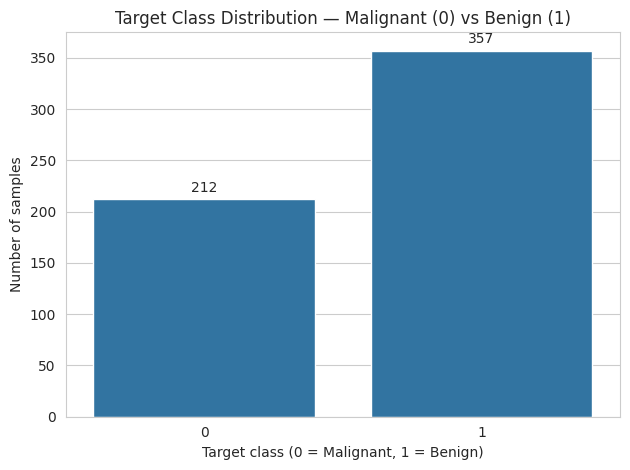

In [4]:
ax = sns.countplot(x=y)

ax.set_title("Target Class Distribution — Malignant (0) vs Benign (1)")
ax.set_xlabel("Target class (0 = Malignant, 1 = Benign)")
ax.set_ylabel("Number of samples")

for container in ax.containers:
    ax.bar_label(container, fmt="%d", padding=3)

plt.tight_layout()
plt.savefig("plots/class_distribution.png", dpi=120)
plt.show()

### Observation: Class Imbalance

There are 212 malignant (about 37%) and 357 benign (about 63%) samples. This is a mild imbalance, not a severe one.
For a dataset of this size I do not think oversampling, undersampling or class weights are needed. I only use a stratified split so both sets keep the same ratio,
and I will look at the recall of the malignant class separately, because accuracy alone can hide mistakes on the smaller class.

### 1.3 - Feature correlation heatmap

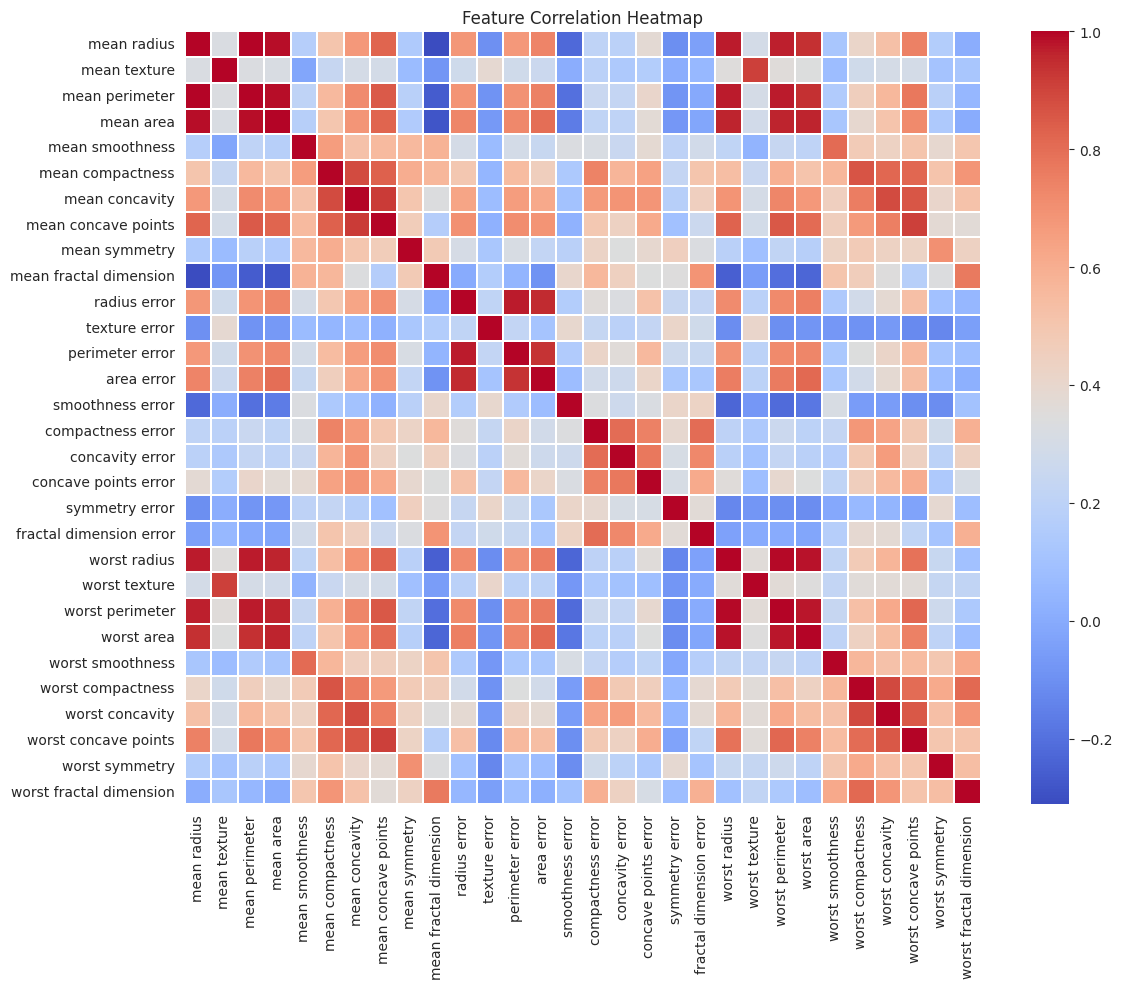

In [5]:
corr = X.corr()

plt.figure(figsize=(12, 10))
sns.heatmap(corr, annot=False, cmap="coolwarm", linewidths=0.3)

plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.savefig("plots/correlation_heatmap.png", dpi=120)
plt.show()

In [6]:
print("mean radius vs mean perimeter  :", round(corr.loc["mean radius", "mean perimeter"], 3))
print("mean radius vs mean area       :", round(corr.loc["mean radius", "mean area"], 3))
print("worst radius vs worst perimeter:", round(corr.loc["worst radius", "worst perimeter"], 3))

mean radius vs mean perimeter  : 0.998
mean radius vs mean area       : 0.987
worst radius vs worst perimeter: 0.994


### Observation: Feature Correlation

Several features are almost perfectly correlated. Examples (sklearn writes the names as `mean radius`, which is `radius_mean` in the UCI file):

1. `mean radius` and `mean perimeter`
2. `mean radius` and `mean area`
3. `worst radius` and `worst perimeter`

This makes sense because perimeter and area are calculated from the radius.

**Is this a problem for neural networks?** Not like it is for linear models. In linear regression, correlated features cause multicollinearity, so the coefficients become unstable and hard to interpret.
A neural network is trained with gradient descent, and we do not interpret single weights. It can share information across many weights, so correlated inputs just give it some redundancy and do not break the training.

### 1.4 - Train / test split

In [7]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("X_train shape:", X_train.shape)
print("X_test shape :", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape :", y_test.shape)

X_train shape: (455, 30)
X_test shape : (114, 30)
y_train shape: (455,)
y_test shape : (114,)


In [8]:
print("Train class proportions:")
print(y_train.value_counts(normalize=True).sort_index().round(3))

print()
print("Test class proportions:")
print(y_test.value_counts(normalize=True).sort_index().round(3))

Train class proportions:
target
0    0.374
1    0.626
Name: proportion, dtype: float64

Test class proportions:
target
0    0.368
1    0.632
Name: proportion, dtype: float64


Both sets keep the original ratio of about 37% malignant and 63% benign, so `stratify=y` worked.

### 1.5 - Apply StandardScaler

In [9]:
scaler = StandardScaler()
scaler.fit(X_train)

X_train_sc = scaler.transform(X_train)
X_test_sc = scaler.transform(X_test)

print("Train means:")
print(X_train_sc.mean(axis=0).round(2))
print()
print("Train standard deviations:")
print(X_train_sc.std(axis=0).round(2))

Train means:
[-0.  0. -0.  0.  0. -0. -0.  0. -0. -0.  0. -0.  0. -0. -0.  0.  0.  0.
  0.  0.  0.  0. -0. -0.  0. -0. -0. -0. -0. -0.]

Train standard deviations:
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1.]


### Observation: Feature Scaling

The scaler is fitted on `X_train` only. If I also fitted it on `X_test`, the mean and standard deviation of the test data would leak into the training process (data leakage)
and the test score would look better than it really is. The test set must behave like new unseen patients, so it is only transformed using the mean and std learned from the training data.

After scaling, the training features have mean 0 and std 1. The test features will be close to these values but not exactly, because they use the training parameters.

### 1.6 - WHY scaling for neural networks

Optimisers like SGD and Adam use gradients, and the gradient for a weight depends on the size of its input feature.
In this dataset `mean area` goes up to about 2500 while `mean fractal dimension` is only around 0.05 to 0.10.
Without scaling the large-range features dominate the early updates and the small-range features hardly contribute, so learning becomes slow and biased.
`StandardScaler` puts every feature at mean 0 and std 1, so all of them contribute fairly and the optimiser converges faster and more stably.

## Task 2: Single-Layer Perceptron (SLP) — Baseline Model
**Objective:** Build the simplest possible neural network (one neuron) and use it as a baseline.

**Expected output:** Model summary with 31 parameters, training curves, test accuracy, classification report and confusion matrix.

### 2.1 - Build the SLP

In [10]:
tf.keras.utils.set_random_seed(42)   # same results every time I run the notebook

model_slp = keras.Sequential([
    keras.Input(shape=(30,)),
    keras.layers.Dense(1, activation="sigmoid")
])

This is a true SLP: one neuron, one weight for each of the 30 features, one bias and no hidden layer.

### 2.2 - Compile the SLP

In [11]:
model_slp.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])

model_slp.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 1)              │            31 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 31 (124.00 B)

 Trainable params: 31 (124.00 B)

 Non-trainable params: 0 (0.00 B)

### Why Binary Cross-Entropy Loss?

The summary shows 31 parameters (30 weights + 1 bias), as expected.

Binary cross-entropy is the correct loss for binary classification because the model outputs a probability and this loss measures how far that probability is from the true label (the log-likelihood).
It punishes confident wrong predictions very heavily. MSE is made for regression, where the output is a continuous value, and with a sigmoid output it gives weak gradients when the model is wrong.

### 2.3 - Train the SLP

In [12]:
history_slp = model_slp.fit(X_train_sc, y_train, epochs=50, batch_size=32, validation_split=0.1, verbose=1)

Epoch 1/50


 1/13 ━━━━━━━━━━━━━━━━━━━━ 17s 1s/step - accuracy: 0.5312 - loss: 0.7971

13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 29ms/step - accuracy: 0.4939 - loss: 0.8112 - val_accuracy: 0.3261 - val_loss: 0.8657


Epoch 2/50


 1/13 ━━━━━━━━━━━━━━━━━━━━ 6s 558ms/step - accuracy: 0.5938 - loss: 0.7108

13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.5868 - loss: 0.7331 - val_accuracy: 0.4783 - val_loss: 0.7958


... (140 outputs left out)

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9682 - loss: 0.1450 - val_accuracy: 0.9565 - val_loss: 0.1782


Epoch 50/50


 1/13 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 1.0000 - loss: 0.1089

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9682 - loss: 0.1429 - val_accuracy: 0.9565 - val_loss: 0.1758


### 2.4 - Plot SLP training curves

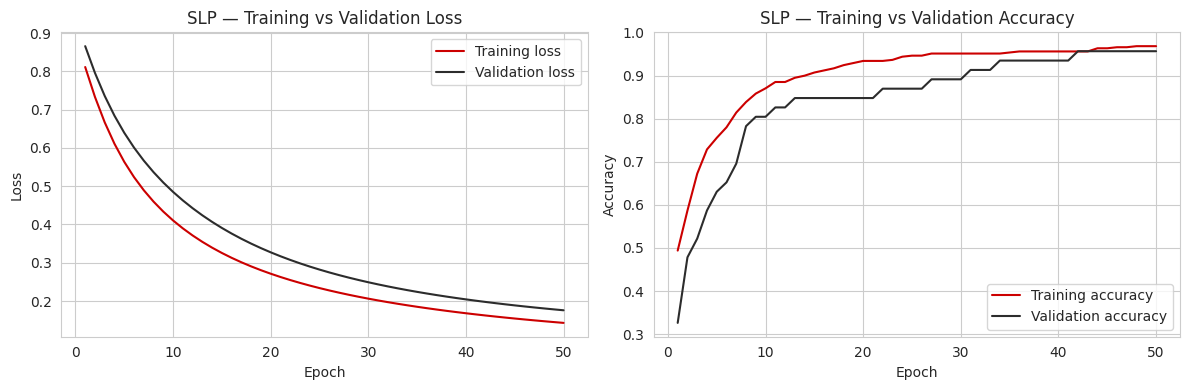

In [13]:
history = history_slp.history
epochs = range(1, len(history["loss"]) + 1)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(epochs, history["loss"], color="#CC0000", label="Training loss")
plt.plot(epochs, history["val_loss"], color="#2C2C2C", label="Validation loss")
plt.title("SLP — Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs, history["accuracy"], color="#CC0000", label="Training accuracy")
plt.plot(epochs, history["val_accuracy"], color="#2C2C2C", label="Validation accuracy")
plt.title("SLP — Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.tight_layout()
plt.savefig("plots/slp_training_curves.png", dpi=120)
plt.show()

### Observation: SLP Learning Curves

The SLP trains very smoothly. The loss goes down steadily without any jumps and is still falling slowly at epoch 50, so it has not fully converged yet.
The validation loss stays a little above the training loss, and the accuracy ends at about 97% (training) vs 96% (validation).
This small gap means the SLP is not overfitting, which is expected for a model with only 31 parameters.
The validation accuracy moves in small steps because the validation split has only 46 samples.

### 2.5 - Evaluate the SLP

In [14]:
slp_loss, slp_acc = model_slp.evaluate(X_test_sc, y_test, verbose=0)
print("SLP test accuracy:", round(slp_acc * 100, 2), "%")

y_pred_slp = (model_slp.predict(X_test_sc, verbose=0) > 0.5).astype(int).ravel()

SLP test accuracy: 94.74 %


In [15]:
print(classification_report(y_test, y_pred_slp, target_names=["Malignant (0)", "Benign (1)"]))

               precision    recall  f1-score   support

Malignant (0)       0.95      0.90      0.93        42
   Benign (1)       0.95      0.97      0.96        72

     accuracy                           0.95       114
    macro avg       0.95      0.94      0.94       114
 weighted avg       0.95      0.95      0.95       114



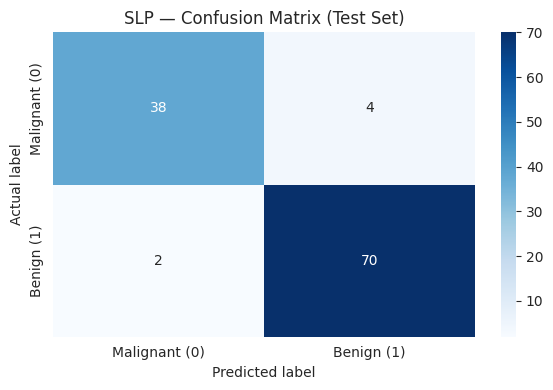

In [16]:
cm_slp = confusion_matrix(y_test, y_pred_slp)

plt.figure(figsize=(6, 4))
sns.heatmap(cm_slp, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Malignant (0)", "Benign (1)"], yticklabels=["Malignant (0)", "Benign (1)"])

plt.title("SLP — Confusion Matrix (Test Set)")
plt.xlabel("Predicted label")
plt.ylabel("Actual label")
plt.tight_layout()
plt.savefig("plots/slp_confusion_matrix.png", dpi=120)
plt.show()

### Observation: SLP Test Results

Test accuracy is 94.74%. For the Malignant class the recall is 0.90, which means the SLP missed 4 of the 42 malignant tumours (it called them Benign),
and 2 benign tumours were wrongly called malignant. This is a good baseline, but missing 4 cancers is exactly the kind of error we want to reduce.

In [17]:
# results table, I add one row after every experiment and build the full table in Task 7
results = pd.DataFrame({"Model": ["SLP"], "Test Accuracy (%)": [round(slp_acc * 100, 2)]})
results

,Model,Test Accuracy (%)
0,SLP,94.74


### 2.6 - SLP limitations

### Limitation of the Single-Layer Perceptron

An SLP is just a sigmoid on top of one weighted sum, so it can only learn a linear decision boundary: one hyperplane through the 30-dimensional feature space.
It works well only if the two classes can be separated by a flat surface. Tumour data is unlikely to be perfectly linearly separable,
so the SLP is a realistic baseline that can still be improved. That is the reason for moving to a Multi-Layer Perceptron in Task 3.

## Task 3: Multi-Layer Perceptron (MLP) — Activation Functions
**Objective:** Add hidden layers to the model and compare ReLU, Tanh and Sigmoid as hidden-layer activations.

**Expected output:** MLP summary with a verified parameter count, a 3-panel activation comparison plot, and the best variant evaluated on the test set.

### 3.1 - Build the MLP (ReLU)

In [18]:
tf.keras.utils.set_random_seed(42)

model_mlp = keras.Sequential([
    keras.Input(shape=(30,)),
    keras.layers.Dense(64, activation="relu"),
    keras.layers.Dense(32, activation="relu"),
    keras.layers.Dense(1, activation="sigmoid")
])

model_mlp.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_1 (Dense)                 │ (None, 64)             │         1,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,097 (16.00 KB)

 Trainable params: 4,097 (16.00 KB)

 Non-trainable params: 0 (0.00 B)

In [19]:
layer1 = 30 * 64 + 64
layer2 = 64 * 32 + 32
layer3 = 32 * 1 + 1

print("Layer 1 parameters     :", layer1)
print("Layer 2 parameters     :", layer2)
print("Output layer parameters:", layer3)
print("Manual total           :", layer1 + layer2 + layer3)
print("Summary total          :", model_mlp.count_params())

Layer 1 parameters     : 1984
Layer 2 parameters     : 2080
Output layer parameters: 33
Manual total           : 4097
Summary total          : 4097


The manual count (weights = inputs × neurons, plus one bias for each neuron) matches the summary: 4,097 parameters.

### 3.2 - WHY hidden layers

### Hidden Layers and Non-Linear Transformations

Each Dense layer applies a weighted sum followed by a non-linear activation, so it learns a new non-linear representation of its input.
With two hidden layers, the second layer combines the features created by the first one, so the network gets a small hierarchy of feature interactions (more layers means a deeper feature hierarchy).
By the Universal Approximation Theorem even one hidden layer can approximate any function in theory, but in practice two layers often converge faster on tabular medical data like this.
The SLP had none of this, it could only draw one straight boundary.

### 3.3 - Compile and train the MLP (ReLU)

In [20]:
model_mlp.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])

In [21]:
history_mlp = model_mlp.fit(X_train_sc, y_train, epochs=100, batch_size=32, validation_split=0.1, verbose=1)

Epoch 1/100


 1/13 ━━━━━━━━━━━━━━━━━━━━ 16s 1s/step - accuracy: 0.5000 - loss: 0.6877

13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 29ms/step - accuracy: 0.7995 - loss: 0.5373 - val_accuracy: 0.9348 - val_loss: 0.3918


Epoch 2/100


 1/13 ━━━━━━━━━━━━━━━━━━━━ 2s 215ms/step - accuracy: 1.0000 - loss: 0.3786

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.9560 - loss: 0.2971 - val_accuracy: 0.9348 - val_loss: 0.2584


... (291 outputs left out)

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 1.0000 - loss: 9.0727e-04 - val_accuracy: 1.0000 - val_loss: 0.0034


Epoch 100/100


 1/13 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 1.0000 - loss: 3.2455e-04

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 1.0000 - loss: 8.8057e-04 - val_accuracy: 1.0000 - val_loss: 0.0034


### 3.4 - Compare activation functions

#### (A) activation = 'tanh'

In [22]:
tf.keras.utils.set_random_seed(42)

model_tanh = keras.Sequential([
    keras.Input(shape=(30,)),
    keras.layers.Dense(64, activation="tanh"),
    keras.layers.Dense(32, activation="tanh"),
    keras.layers.Dense(1, activation="sigmoid")
])

model_tanh.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
history_tanh = model_tanh.fit(X_train_sc, y_train, epochs=100, batch_size=32, validation_split=0.1, verbose=1)

Epoch 1/100


 1/13 ━━━━━━━━━━━━━━━━━━━━ 20s 2s/step - accuracy: 0.6875 - loss: 0.6033

13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 34ms/step - accuracy: 0.9242 - loss: 0.3589 - val_accuracy: 0.9565 - val_loss: 0.2313


Epoch 2/100


 1/13 ━━━━━━━━━━━━━━━━━━━━ 2s 204ms/step - accuracy: 1.0000 - loss: 0.1585

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.9584 - loss: 0.1552 - val_accuracy: 0.9348 - val_loss: 0.1696


... (292 outputs left out)

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 1.0000 - loss: 0.0028 - val_accuracy: 0.9565 - val_loss: 0.1388


Epoch 100/100


 1/13 ━━━━━━━━━━━━━━━━━━━━ 1s 160ms/step - accuracy: 1.0000 - loss: 3.7534e-04

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 1.0000 - loss: 0.0027 - val_accuracy: 0.9565 - val_loss: 0.1401


#### (B) activation = 'sigmoid'

In [23]:
tf.keras.utils.set_random_seed(42)

model_sigmoid = keras.Sequential([
    keras.Input(shape=(30,)),
    keras.layers.Dense(64, activation="sigmoid"),
    keras.layers.Dense(32, activation="sigmoid"),
    keras.layers.Dense(1, activation="sigmoid")
])

model_sigmoid.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
history_sigmoid = model_sigmoid.fit(X_train_sc, y_train, epochs=100, batch_size=32, validation_split=0.1, verbose=1)

Epoch 1/100


 1/13 ━━━━━━━━━━━━━━━━━━━━ 14s 1s/step - accuracy: 0.4062 - loss: 0.7318

13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step - accuracy: 0.6186 - loss: 0.6692 - val_accuracy: 0.5000 - val_loss: 0.6391


Epoch 2/100


 1/13 ━━━━━━━━━━━━━━━━━━━━ 3s 257ms/step - accuracy: 0.6250 - loss: 0.6099

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.6601 - loss: 0.5646 - val_accuracy: 0.5217 - val_loss: 0.6099


... (292 outputs left out)

Epoch 100/100


 1/13 ━━━━━━━━━━━━━━━━━━━━ 1s 165ms/step - accuracy: 1.0000 - loss: 0.0066

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9902 - loss: 0.0377  

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.9902 - loss: 0.0377 - val_accuracy: 0.9783 - val_loss: 0.0478


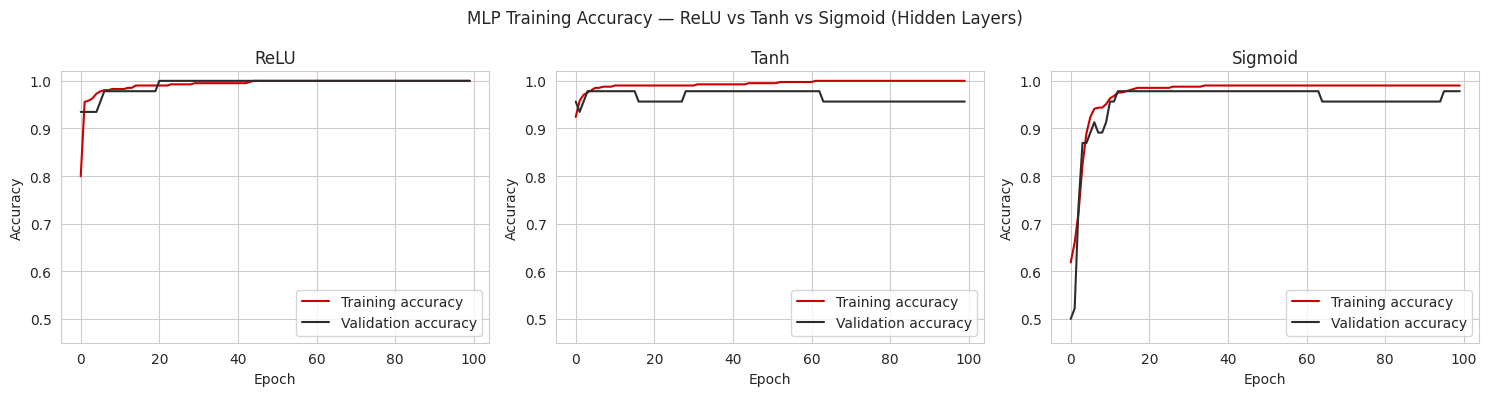

In [24]:
names = ["ReLU", "Tanh", "Sigmoid"]
histories = [history_mlp, history_tanh, history_sigmoid]

plt.figure(figsize=(15, 4))

for i in range(3):
    plt.subplot(1, 3, i + 1)
    plt.plot(histories[i].history["accuracy"], color="#CC0000", label="Training accuracy")
    plt.plot(histories[i].history["val_accuracy"], color="#2C2C2C", label="Validation accuracy")
    plt.title(names[i])
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.ylim(0.45, 1.02)
    plt.legend(loc="lower right")

plt.suptitle("MLP Training Accuracy — ReLU vs Tanh vs Sigmoid (Hidden Layers)")
plt.tight_layout()
plt.savefig("plots/activation_comparison.png", dpi=120)
plt.show()

In [25]:
act_table = pd.DataFrame({
    "Final Train Accuracy": [h.history["accuracy"][-1] for h in histories],
    "Final Val Accuracy": [h.history["val_accuracy"][-1] for h in histories],
    "Final Val Loss": [h.history["val_loss"][-1] for h in histories]
}, index=names)

act_table.round(4)

,Final Train Accuracy,Final Val Accuracy,Final Val Loss
ReLU,1.0000,1.0000,0.0034
Tanh,1.0000,0.9565,0.1401
Sigmoid,0.9902,0.9783,0.0478


### 3.5 - Activation functions

- **ReLU:** `max(0, x)`. It has no vanishing gradient for positive inputs and is cheap to compute, so it usually converges fastest on tabular data. The risk is the "dying ReLU": a neuron that always gets negative input has zero gradient and stops learning.
- **Tanh:** output between -1 and 1. It is zero-centred, which is better than Sigmoid, but its gradient becomes very small for large inputs, so it can suffer from vanishing gradients in deep networks.
- **Sigmoid in hidden layers:** output between 0 and 1, not zero-centred, and its gradient is at most 0.25, so gradients shrink quickly in deep networks. It should be kept only for the output layer of a binary classifier.

**Which one performed best here:** ReLU, with a final validation accuracy of 1.0 and by far the lowest validation loss (0.0034, against 0.0478 for Sigmoid and 0.1401 for Tanh).
Tanh learned very fast in the first epochs, but it ended with a training accuracy of 1.0 and a validation accuracy of 0.9565, so it overfitted the most (highest validation loss).
Sigmoid started the slowest (about 0.62 training accuracy after the first epoch, compared with 0.80 for ReLU and 0.93 for Tanh), which matches the theory about weak gradients.

One honest point: all three reach a similar accuracy because the network has only two hidden layers, so vanishing gradients are not a big problem here.
The validation set is also small (46 samples), so the ranking is only a hint and not strong proof. I chose ReLU as the best variant.

### 3.6 - Evaluate the best MLP

In [26]:
# best variant = highest final validation accuracy (lower validation loss breaks a tie)
best_act = act_table.sort_values(["Final Val Accuracy", "Final Val Loss"], ascending=[False, True]).index[0]
best_mlp = {"ReLU": model_mlp, "Tanh": model_tanh, "Sigmoid": model_sigmoid}[best_act]

best_loss, best_acc = best_mlp.evaluate(X_test_sc, y_test, verbose=0)
print("Best activation:", best_act)
print("Test accuracy  :", round(best_acc * 100, 2), "%")

y_pred_mlp = (best_mlp.predict(X_test_sc, verbose=0) > 0.5).astype(int).ravel()

Best activation: ReLU
Test accuracy  : 96.49 %


In [27]:
print(classification_report(y_test, y_pred_mlp, target_names=["Malignant (0)", "Benign (1)"]))

               precision    recall  f1-score   support

Malignant (0)       0.93      0.98      0.95        42
   Benign (1)       0.99      0.96      0.97        72

     accuracy                           0.96       114
    macro avg       0.96      0.97      0.96       114
 weighted avg       0.97      0.96      0.97       114



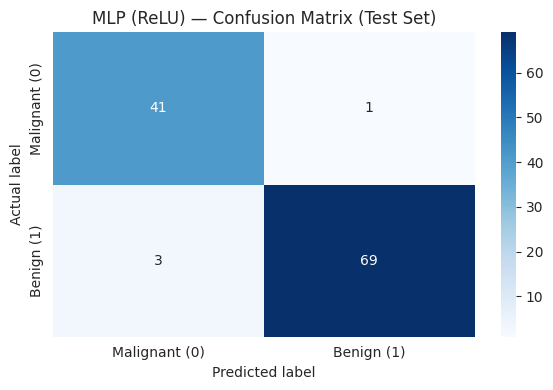

In [28]:
cm_mlp = confusion_matrix(y_test, y_pred_mlp)

plt.figure(figsize=(6, 4))
sns.heatmap(cm_mlp, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Malignant (0)", "Benign (1)"], yticklabels=["Malignant (0)", "Benign (1)"])

plt.title(f"MLP ({best_act}) — Confusion Matrix (Test Set)")
plt.xlabel("Predicted label")
plt.ylabel("Actual label")
plt.tight_layout()
plt.savefig("plots/mlp_confusion_matrix.png", dpi=120)
plt.show()

In [29]:
results.loc[len(results)] = [f"MLP ({best_act})", round(best_acc * 100, 2)]
print(results.to_string(index=False))
print()
print(f"MLP improvement over SLP: {(best_acc - slp_acc) * 100:+.2f} percentage points")

     Model  Test Accuracy (%)
       SLP              94.74
MLP (ReLU)              96.49

MLP improvement over SLP: +1.75 percentage points


### Observation: MLP vs SLP

Test accuracy went from 94.74% (SLP) to 96.49% (MLP-ReLU), an improvement of 1.75 percentage points. The most important change is the malignant recall: it rose from 0.90 to 0.98,
so the number of missed malignant tumours fell from 4 to 1. The price is that the malignant precision dropped a little (0.95 to 0.93), because 3 benign tumours were called malignant.
So the hidden layers helped, as expected from the SLP limitation.

## Task 4: Early Stopping
**Objective:** Train a bigger MLP for many epochs and use Early Stopping to stop before it overfits.

**Expected output:** Training curves with the stopping epoch marked, and a comparison of the model with and without Early Stopping.

### 4.1 - Build MLP for the Early Stopping experiment

In [30]:
tf.keras.utils.set_random_seed(42)

model_overfit = keras.Sequential([
    keras.Input(shape=(30,)),
    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dense(64, activation="relu"),
    keras.layers.Dense(1, activation="sigmoid")
])

model_overfit.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
model_overfit.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_10 (Dense)                │ (None, 128)            │         3,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,289 (48.00 KB)

 Trainable params: 12,289 (48.00 KB)

 Non-trainable params: 0 (0.00 B)

In [31]:
# 300 epochs with no callback, so overfitting can happen naturally
history_overfit = model_overfit.fit(X_train_sc, y_train, epochs=300, batch_size=32, validation_split=0.1, verbose=1)

Epoch 1/300


 1/13 ━━━━━━━━━━━━━━━━━━━━ 17s 1s/step - accuracy: 0.5625 - loss: 0.6889

13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step - accuracy: 0.8753 - loss: 0.4476 - val_accuracy: 0.8913 - val_loss: 0.3377


Epoch 2/300


 1/13 ━━━━━━━━━━━━━━━━━━━━ 3s 257ms/step - accuracy: 0.9375 - loss: 0.2602

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.9511 - loss: 0.1975 - val_accuracy: 0.9130 - val_loss: 0.2122


... (898 outputs left out)

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 1.0000 - loss: 1.2438e-05 - val_accuracy: 0.9783 - val_loss: 0.0447


Epoch 300/300


 1/13 ━━━━━━━━━━━━━━━━━━━━ 1s 128ms/step - accuracy: 1.0000 - loss: 6.3335e-06

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 1.0000 - loss: 1.2305e-05 - val_accuracy: 0.9783 - val_loss: 0.0449


### 4.2 - Add the EarlyStopping callback

In [32]:
tf.keras.utils.set_random_seed(42)

model_es = keras.Sequential([
    keras.Input(shape=(30,)),
    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dense(64, activation="relu"),
    keras.layers.Dense(1, activation="sigmoid")
])

model_es.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])

es = EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True, verbose=1)

history_es = model_es.fit(X_train_sc, y_train, epochs=300, batch_size=32, validation_split=0.1, callbacks=[es], verbose=1)

Epoch 1/300


 1/13 ━━━━━━━━━━━━━━━━━━━━ 20s 2s/step - accuracy: 0.5625 - loss: 0.6889

13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - accuracy: 0.8753 - loss: 0.4476 - val_accuracy: 0.8913 - val_loss: 0.3377


Epoch 2/300


 1/13 ━━━━━━━━━━━━━━━━━━━━ 1s 153ms/step - accuracy: 0.9375 - loss: 0.2602

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.9511 - loss: 0.1975 - val_accuracy: 0.9130 - val_loss: 0.2122


... (184 outputs left out)

 1/13 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 1.0000 - loss: 4.6758e-04

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 1.0000 - loss: 8.8707e-04 - val_accuracy: 1.0000 - val_loss: 0.0315


Epoch 64: early stopping


Restoring model weights from the end of the best epoch: 49.


### 4.3 - WHY Early Stopping

### Understanding the EarlyStopping Parameters

1. **`monitor="val_loss"`**: the callback watches the validation loss, not the training loss, because the training loss keeps going down even when the model is just memorising the training data. Only the validation loss shows how well the model generalises.
2. **`patience=15`**: training is allowed to continue for 15 epochs in a row without improvement before it stops. The validation loss is noisy, so this avoids stopping on a small temporary plateau.
3. **`restore_best_weights=True`**: after stopping, the weights go back to the epoch with the lowest val_loss. Without this the final model would keep the weights of the last epoch, which is 15 epochs after the best one (already overfitting).
4. **`verbose=1`**: prints a message with the epoch at which training stopped.

### 4.4 - Plot Early Stopping curves

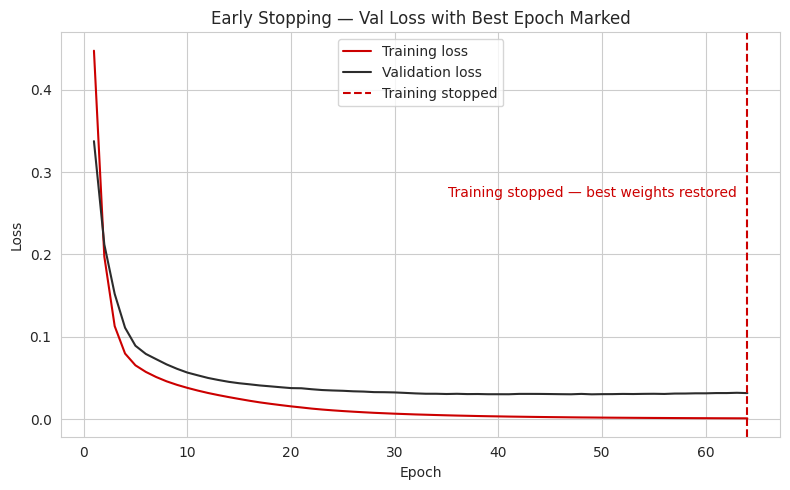

In [33]:
stop_epoch = len(history_es.history["loss"])
epochs = range(1, stop_epoch + 1)

plt.figure(figsize=(8, 5))
plt.plot(epochs, history_es.history["loss"], color="#CC0000", label="Training loss")
plt.plot(epochs, history_es.history["val_loss"], color="#2C2C2C", label="Validation loss")

plt.axvline(stop_epoch, color="#CC0000", linestyle="--", label="Training stopped")
plt.text(stop_epoch - 1, max(history_es.history["val_loss"]) * 0.8, "Training stopped — best weights restored",
         color="#CC0000", ha="right")

plt.title("Early Stopping — Val Loss with Best Epoch Marked")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.tight_layout()
plt.savefig("plots/early_stopping_curves.png", dpi=120)
plt.show()

### Observation: Early Stopping Curve

Training stopped at epoch 64. Because `patience=15`, the best epoch was 15 epochs earlier, at epoch 49, and `restore_best_weights=True` put the weights of that epoch back.
The training loss keeps going down in the plot, while the validation loss stops improving. That is the start of overfitting.

### 4.5 - Compare: with vs without Early Stopping

The second identical MLP trained for the full 300 epochs without a callback is `model_overfit` from 4.1.
Both models use the same architecture and the same seed, so I do not train it a second time.

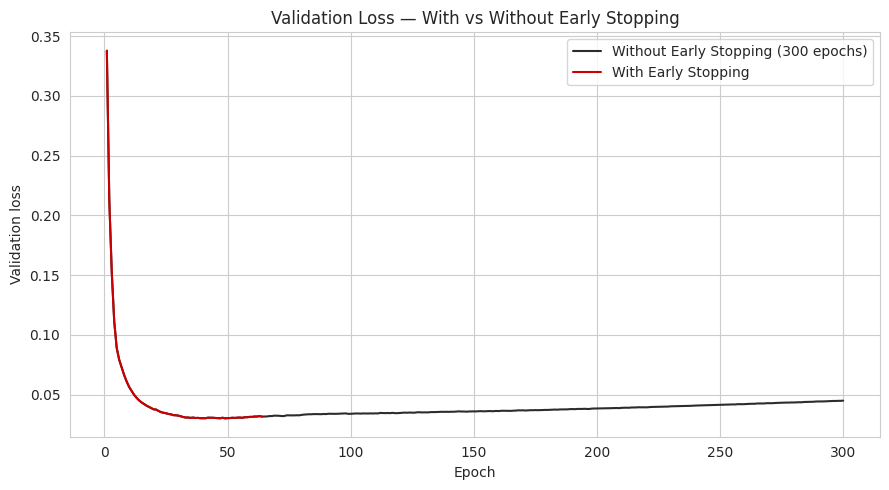

In [34]:
plt.figure(figsize=(9, 5))
plt.plot(range(1, len(history_overfit.history["val_loss"]) + 1), history_overfit.history["val_loss"],
         color="#2C2C2C", label="Without Early Stopping (300 epochs)")
plt.plot(range(1, stop_epoch + 1), history_es.history["val_loss"], color="#CC0000", label="With Early Stopping")

plt.title("Validation Loss — With vs Without Early Stopping")
plt.xlabel("Epoch")
plt.ylabel("Validation loss")
plt.legend()
plt.tight_layout()
plt.savefig("plots/early_stopping_comparison.png", dpi=120)
plt.show()

In [35]:
val_no_es = history_overfit.history["val_loss"]
val_es = history_es.history["val_loss"]

print("Without Early Stopping: lowest val_loss", round(min(val_no_es), 4), "at epoch", np.argmin(val_no_es) + 1)
print("Without Early Stopping: val_loss at epoch 300 =", round(val_no_es[-1], 4))
print("With Early Stopping   : best val_loss", round(min(val_es), 4), "| training stopped at epoch", stop_epoch)

Without Early Stopping: lowest val_loss 0.0301 at epoch 49
Without Early Stopping: val_loss at epoch 300 = 0.0449
With Early Stopping   : best val_loss 0.0301 | training stopped at epoch 64


In [36]:
loss_no_es, acc_no_es = model_overfit.evaluate(X_test_sc, y_test, verbose=0)
loss_es, acc_es = model_es.evaluate(X_test_sc, y_test, verbose=0)

print("Test accuracy without Early Stopping:", round(acc_no_es * 100, 2), "%")
print("Test accuracy with Early Stopping   :", round(acc_es * 100, 2), "%")

results.loc[len(results)] = ["MLP + Early Stopping", round(acc_es * 100, 2)]

Test accuracy without Early Stopping: 97.37 %
Test accuracy with Early Stopping   : 96.49 %


### Observation: With vs Without Early Stopping

Both models start from the same weights, so their curves are identical until Early Stopping ends the first one.
In the model without a callback, the validation loss was lowest at epoch 49 (0.0301) and then started rising (overfitting begins around epoch 49 to 50), reaching 0.0449 at epoch 300, which is about 49% worse.
The Early Stopping model kept the best value (0.0301), so its val_loss is lower, and it needed only 64 epochs instead of 300.

On the test set the two models are almost the same: 96.49% with Early Stopping and 97.37% without it (a difference of one test sample out of 114).
So in this run Early Stopping improved the validation loss, but not the test accuracy. This can happen because an overfitted network becomes over-confident
(the loss increases) without changing many of its final yes/no predictions.

## Task 5: Dropout Layers
**Objective:** Add Dropout to reduce overfitting and find out which dropout rate works best.

**Expected output:** Dropout model summary, validation accuracy comparison for rates 0.1 / 0.3 / 0.5, and test evaluation of the best one.

### 5.1 - Build MLP with Dropout

In [37]:
tf.keras.utils.set_random_seed(42)

model_drop = keras.Sequential([
    keras.Input(shape=(30,)),
    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(64, activation="relu"),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(1, activation="sigmoid")
])

model_drop.summary()

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_16 (Dense)                │ (None, 128)            │         3,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,289 (48.00 KB)

 Trainable params: 12,289 (48.00 KB)

 Non-trainable params: 0 (0.00 B)

The Dropout layers have 0 parameters. They have nothing to learn and only switch off random activations during training.

### 5.2 - WHY Dropout

### How Dropout Reduces Overfitting

1. **Randomly dropping neurons:** `Dropout(0.3)` sets 30% of the neuron outputs to zero in every training batch.
2. **Redundant representations:** because any neuron can disappear at any step, the network cannot depend on a few neurons and has to spread the knowledge across many of them.
3. **At inference time:** Dropout is switched off automatically in `model.predict()`, so all neurons are used. The outputs stay on the same scale because Keras divides the kept activations by the keep probability (0.7) during training.
4. **Ensemble view:** Dropout is like training an ensemble of many thinned networks (2^n possible sub-networks) that share weights, and the final model is like the average of all of them. Averaging reduces variance and improves generalisation.

### 5.3 - Train with Dropout + Early Stopping

In [38]:
model_drop.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])

es_drop = EarlyStopping(monitor="val_loss", patience=20, restore_best_weights=True, verbose=1)

history_drop = model_drop.fit(X_train_sc, y_train, epochs=300, batch_size=32, validation_split=0.1, callbacks=[es_drop], verbose=1)

Epoch 1/300


 1/13 ━━━━━━━━━━━━━━━━━━━━ 25s 2s/step - accuracy: 0.4375 - loss: 0.7879

12/13 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7708 - loss: 0.5103

13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 38ms/step - accuracy: 0.7800 - loss: 0.5013 - val_accuracy: 0.8913 - val_loss: 0.3399


Epoch 2/300


 1/13 ━━━━━━━━━━━━━━━━━━━━ 1s 161ms/step - accuracy: 0.9375 - loss: 0.3072

... (379 outputs left out)

11/13 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 1.0000 - loss: 0.0023     

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 1.0000 - loss: 0.0020 - val_accuracy: 1.0000 - val_loss: 0.0060


Epoch 122: early stopping


Restoring model weights from the end of the best epoch: 102.


### 5.4 - Effect of Dropout rate

#### Model with Dropout rate 0.1

In [39]:
tf.keras.utils.set_random_seed(42)

model_drop_01 = keras.Sequential([
    keras.Input(shape=(30,)),
    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dropout(0.1),
    keras.layers.Dense(64, activation="relu"),
    keras.layers.Dropout(0.1),
    keras.layers.Dense(1, activation="sigmoid")
])

model_drop_01.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])

es_drop_01 = EarlyStopping(monitor="val_loss", patience=20, restore_best_weights=True, verbose=1)

history_drop_01 = model_drop_01.fit(X_train_sc, y_train, epochs=200, batch_size=32, validation_split=0.1, callbacks=[es_drop_01], verbose=1)

Epoch 1/200


 1/13 ━━━━━━━━━━━━━━━━━━━━ 23s 2s/step - accuracy: 0.4062 - loss: 0.7609

13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 35ms/step - accuracy: 0.8655 - loss: 0.4540 - val_accuracy: 0.8913 - val_loss: 0.3184


Epoch 2/200


 1/13 ━━━━━━━━━━━━━━━━━━━━ 2s 200ms/step - accuracy: 0.9688 - loss: 0.2633

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9584 - loss: 0.2026 - val_accuracy: 0.9130 - val_loss: 0.2149


... (255 outputs left out)

 1/13 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 1.0000 - loss: 0.0015

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 1.0000 - loss: 0.0017 - val_accuracy: 1.0000 - val_loss: 0.0181


Epoch 84: early stopping


Restoring model weights from the end of the best epoch: 64.


#### Model with Dropout rate 0.5

In [40]:
tf.keras.utils.set_random_seed(42)

model_drop_05 = keras.Sequential([
    keras.Input(shape=(30,)),
    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dropout(0.5),
    keras.layers.Dense(64, activation="relu"),
    keras.layers.Dropout(0.5),
    keras.layers.Dense(1, activation="sigmoid")
])

model_drop_05.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])

es_drop_05 = EarlyStopping(monitor="val_loss", patience=20, restore_best_weights=True, verbose=1)

history_drop_05 = model_drop_05.fit(X_train_sc, y_train, epochs=200, batch_size=32, validation_split=0.1, callbacks=[es_drop_05], verbose=1)

Epoch 1/200


 1/13 ━━━━━━━━━━━━━━━━━━━━ 18s 2s/step - accuracy: 0.4062 - loss: 0.9184

12/13 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7031 - loss: 0.5884

13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 46ms/step - accuracy: 0.7115 - loss: 0.5770 - val_accuracy: 0.8913 - val_loss: 0.3843


Epoch 2/200


 1/13 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - accuracy: 0.9375 - loss: 0.3449

... (355 outputs left out)

 1/13 ━━━━━━━━━━━━━━━━━━━━ 1s 129ms/step - accuracy: 1.0000 - loss: 6.2852e-04

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 1.0000 - loss: 0.0052 - val_accuracy: 1.0000 - val_loss: 0.0075


Epoch 118: early stopping


Restoring model weights from the end of the best epoch: 98.


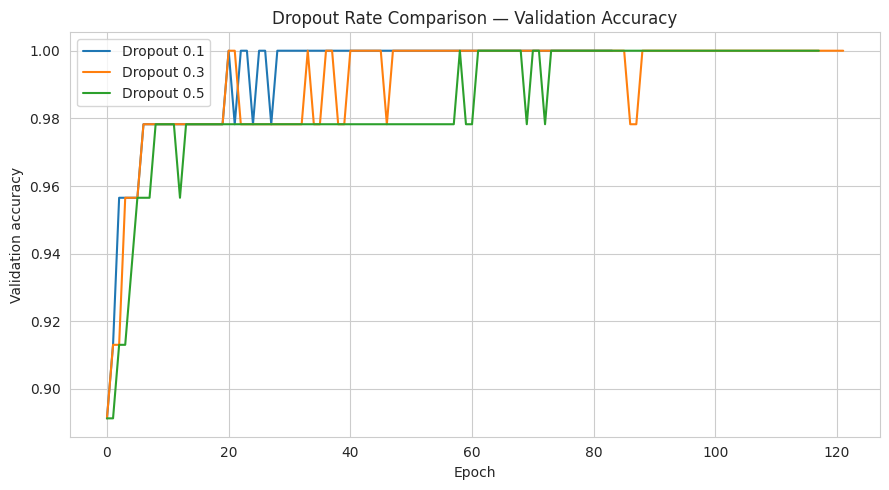

In [41]:
plt.figure(figsize=(9, 5))
plt.plot(history_drop_01.history["val_accuracy"], label="Dropout 0.1")
plt.plot(history_drop.history["val_accuracy"], label="Dropout 0.3")
plt.plot(history_drop_05.history["val_accuracy"], label="Dropout 0.5")

plt.title("Dropout Rate Comparison — Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Validation accuracy")
plt.legend()
plt.tight_layout()
plt.savefig("plots/dropout_rate_comparison.png", dpi=120)
plt.show()

In [42]:
drop_rates = [0.1, 0.3, 0.5]
drop_histories = [history_drop_01, history_drop, history_drop_05]

drop_table = pd.DataFrame({
    "Epochs Trained": [len(h.history["loss"]) for h in drop_histories],
    "Best Val Loss": [min(h.history["val_loss"]) for h in drop_histories],
    "Best Val Accuracy": [max(h.history["val_accuracy"]) for h in drop_histories]
}, index=drop_rates)
drop_table.index.name = "Dropout Rate"

drop_table.round(4)

,Epochs Trained,Best Val Loss,Best Val Accuracy
Dropout Rate,,,
0.1,84,0.0131,1.0
0.3,122,0.0047,1.0
0.5,118,0.0036,1.0


### Observation: Dropout Rate Trade-off

Dropout 0.1 gives too little regularization: the network can still rely on specific neurons, so it overfits earlier (Early Stopping ended at epoch 84) and has the highest validation loss (0.0131).
Dropout 0.5 removes half of the activations in each batch, so every step is noisier and learning becomes slower. If it is too high, the network underfits.

In my run all three rates reached a best validation accuracy of 1.0, so accuracy cannot separate them on a 46-sample validation set. The validation loss can:
0.1 → 0.0131, 0.3 → 0.0047, 0.5 → 0.0036. The higher rates trained longer (122 and 118 epochs) and reached a lower loss.
I did not see clear underfitting at 0.5 on this small and easy dataset, so I selected 0.5 as the best (lowest validation loss), though 0.3 and 0.5 are very close.

### 5.5 - Evaluate the Dropout model

In [43]:
# best dropout rate = lowest validation loss
best_rate = drop_table["Best Val Loss"].idxmin()
best_drop = [model_drop_01, model_drop, model_drop_05][drop_rates.index(best_rate)]

drop_loss, drop_acc = best_drop.evaluate(X_test_sc, y_test, verbose=0)
print("Best dropout rate:", best_rate)
print("Test accuracy    :", round(drop_acc * 100, 2), "%")

results.loc[len(results)] = [f"MLP + Dropout ({best_rate})", round(drop_acc * 100, 2)]

Best dropout rate: 0.5
Test accuracy    : 95.61 %


In [44]:
# training vs validation accuracy at each model's best epoch (the epoch with the lowest val_loss)
best_drop_history = drop_histories[drop_rates.index(best_rate)]

for name, h in [("Without Dropout", history_es), (f"With Dropout {best_rate}", best_drop_history)]:
    best_epoch = np.argmin(h.history["val_loss"])
    train_acc = h.history["accuracy"][best_epoch]
    val_acc = h.history["val_accuracy"][best_epoch]
    print(f"{name:20s} train = {train_acc:.4f} | val = {val_acc:.4f} | gap = {train_acc - val_acc:+.4f}")

Without Dropout      train = 1.0000 | val = 1.0000 | gap = +0.0000
With Dropout 0.5     train = 0.9951 | val = 1.0000 | gap = -0.0049


### Observation: Dropout Result

The best Dropout model (rate 0.5) has a test accuracy of 95.61%, a bit lower than the plain Early Stopping MLP (96.49%), a difference of one test sample.
For training vs validation accuracy at the best epoch, both models have a gap close to zero (train 1.0 vs val 1.0 without Dropout, train 0.995 vs val 1.0 with Dropout),
so this dataset does not show the "smaller gap with Dropout" effect clearly. Also note that the training accuracy with Dropout is measured while neurons are switched off, so it is slightly pessimistic.

## Task 6: Regularization (L1, L2, L1-L2)
**Objective:** Penalise large weights with L1, L2 and L1-L2 (ElasticNet) and compare them.

**Expected output:** Three regularized models, a 3-panel loss comparison plot and a bar chart of test accuracy.

### 6.1 - Build MLP with L2 Regularization

In [45]:
tf.keras.utils.set_random_seed(42)

model_l2 = keras.Sequential([
    keras.Input(shape=(30,)),
    keras.layers.Dense(128, activation="relu", kernel_regularizer=regularizers.l2(0.001)),
    keras.layers.Dense(64, activation="relu", kernel_regularizer=regularizers.l2(0.001)),
    keras.layers.Dense(1, activation="sigmoid")
])

model_l2.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])

es_l2 = EarlyStopping(monitor="val_loss", patience=20, restore_best_weights=True, verbose=1)

history_l2 = model_l2.fit(X_train_sc, y_train, epochs=300, batch_size=32, validation_split=0.1, callbacks=[es_l2], verbose=1)

Epoch 1/300


 1/13 ━━━━━━━━━━━━━━━━━━━━ 14s 1s/step - accuracy: 0.5625 - loss: 0.8229

13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 34ms/step - accuracy: 0.8753 - loss: 0.5809 - val_accuracy: 0.8913 - val_loss: 0.4700


Epoch 2/300


 1/13 ━━━━━━━━━━━━━━━━━━━━ 2s 215ms/step - accuracy: 0.9375 - loss: 0.3932

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.9511 - loss: 0.3294 - val_accuracy: 0.9130 - val_loss: 0.3427


... (470 outputs left out)

 1/13 ━━━━━━━━━━━━━━━━━━━━ 2s 177ms/step - accuracy: 1.0000 - loss: 0.0137

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 1.0000 - loss: 0.0150 - val_accuracy: 0.9783 - val_loss: 0.0472


Epoch 157: early stopping


Restoring model weights from the end of the best epoch: 137.


### 6.2 - WHY L2 Regularization

### Understanding L2 Regularization

L2 adds `λ × Σw²` to the loss in every training step. Large weights are penalised the most, so all the weights are pushed towards zero but never become exactly zero.
The model then uses many small weights instead of a few dominant ones, which gives a smoother decision boundary and less overfitting (lower variance).
`λ = 0.001` is a moderate penalty. If λ is too large, the weights get shrunk too much and the model underfits.

### 6.3 - Build MLP with L1 Regularization

In [46]:
tf.keras.utils.set_random_seed(42)

model_l1 = keras.Sequential([
    keras.Input(shape=(30,)),
    keras.layers.Dense(128, activation="relu", kernel_regularizer=regularizers.l1(0.001)),
    keras.layers.Dense(64, activation="relu", kernel_regularizer=regularizers.l1(0.001)),
    keras.layers.Dense(1, activation="sigmoid")
])

model_l1.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])

es_l1 = EarlyStopping(monitor="val_loss", patience=20, restore_best_weights=True, verbose=1)

history_l1 = model_l1.fit(X_train_sc, y_train, epochs=300, batch_size=32, validation_split=0.1, callbacks=[es_l1], verbose=1)

Epoch 1/300


 1/13 ━━━━━━━━━━━━━━━━━━━━ 17s 1s/step - accuracy: 0.5625 - loss: 1.7855

13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 28ms/step - accuracy: 0.8753 - loss: 1.5292 - val_accuracy: 0.8913 - val_loss: 1.3997


Epoch 2/300


 1/13 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.9375 - loss: 1.3224

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9511 - loss: 1.2401 - val_accuracy: 0.9130 - val_loss: 1.2281


... (897 outputs left out)

Epoch 300/300


 1/13 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 1.0000 - loss: 0.0285

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 1.0000 - loss: 0.0340 - val_accuracy: 1.0000 - val_loss: 0.0457


Restoring model weights from the end of the best epoch: 300.


### L1 vs L2

L1 adds `λ × Σ|w|` instead. The difference from L2 is that the L1 penalty has a constant slope even for tiny weights, so it keeps pushing them all the way to exactly zero.
This gives sparse weights and works like automatic feature selection. On a 30-feature dataset like this, L1 can switch off the weights of weakly predictive features.

### 6.4 - Build MLP with L1-L2 (ElasticNet)

In [47]:
tf.keras.utils.set_random_seed(42)

model_l1l2 = keras.Sequential([
    keras.Input(shape=(30,)),
    keras.layers.Dense(128, activation="relu", kernel_regularizer=regularizers.l1_l2(l1=0.0001, l2=0.001)),
    keras.layers.Dense(64, activation="relu", kernel_regularizer=regularizers.l1_l2(l1=0.0001, l2=0.001)),
    keras.layers.Dense(1, activation="sigmoid")
])

model_l1l2.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])

es_l1l2 = EarlyStopping(monitor="val_loss", patience=20, restore_best_weights=True, verbose=1)

history_l1l2 = model_l1l2.fit(X_train_sc, y_train, epochs=300, batch_size=32, validation_split=0.1, callbacks=[es_l1l2], verbose=1)

Epoch 1/300


 1/13 ━━━━━━━━━━━━━━━━━━━━ 18s 2s/step - accuracy: 0.5625 - loss: 0.9326

13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 42ms/step - accuracy: 0.8753 - loss: 0.6897 - val_accuracy: 0.8913 - val_loss: 0.5778


Epoch 2/300


 1/13 ━━━━━━━━━━━━━━━━━━━━ 1s 122ms/step - accuracy: 0.9375 - loss: 0.5006

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9511 - loss: 0.4361 - val_accuracy: 0.9130 - val_loss: 0.4480


... (725 outputs left out)

 1/13 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 1.0000 - loss: 0.0176

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 1.0000 - loss: 0.0193 - val_accuracy: 0.9783 - val_loss: 0.0423


Epoch 241: early stopping


Restoring model weights from the end of the best epoch: 221.


### Why ElasticNet

ElasticNet uses both penalties together. L2 handles correlated features by sharing the weight between them (this dataset has many, like radius, perimeter and area),
while L1 pushes the weights of really uninformative features to zero.

### 6.5 - Regularization comparison plot

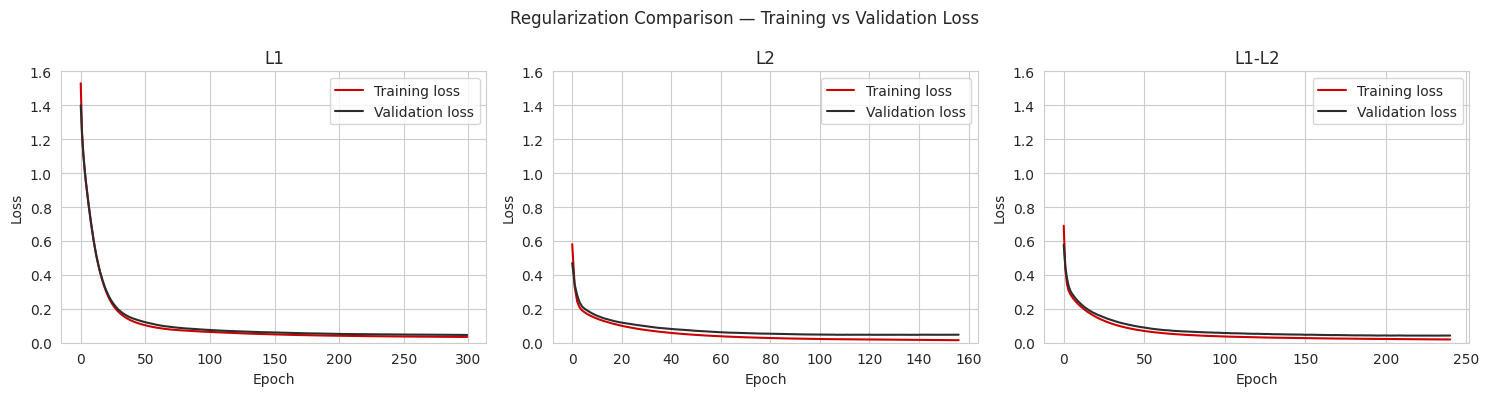

In [48]:
reg_names = ["L1", "L2", "L1-L2"]
reg_histories = [history_l1, history_l2, history_l1l2]

plt.figure(figsize=(15, 4))

for i in range(3):
    plt.subplot(1, 3, i + 1)
    h = reg_histories[i].history
    plt.plot(h["loss"], color="#CC0000", label="Training loss")
    plt.plot(h["val_loss"], color="#2C2C2C", label="Validation loss")
    plt.ylim(0, 1.6)   # same y-axis for all three panels
    plt.title(reg_names[i])
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()

plt.suptitle("Regularization Comparison — Training vs Validation Loss")
plt.tight_layout()
plt.savefig("plots/regularization_comparison.png", dpi=120)
plt.show()

In [49]:
rows = []
for name, h in zip(reg_names, reg_histories):
    best_epoch = np.argmin(h.history["val_loss"])
    rows.append({
        "Regularizer": name,
        "Epochs Trained": len(h.history["loss"]),
        "Train Loss": h.history["loss"][best_epoch],
        "Val Loss": h.history["val_loss"][best_epoch],
        "Loss Gap": h.history["val_loss"][best_epoch] - h.history["loss"][best_epoch],
        "Val Accuracy": h.history["val_accuracy"][best_epoch]
    })

pd.DataFrame(rows).set_index("Regularizer").round(4)

,Epochs Trained,Train Loss,Val Loss,Loss Gap,Val Accuracy
Regularizer,,,,,
L1,300,0.0340,0.0457,0.0118,1.0000
L2,157,0.0166,0.0464,0.0298,0.9783
L1-L2,241,0.0205,0.0417,0.0212,0.9783


### Observation: Regularization Comparison

The smallest train–validation loss gap is with L1 (0.0118), followed by L1-L2 (0.0212) and L2 (0.0298). L1 also had the best validation accuracy (1.0 vs 0.9783 for the other two),
and L1-L2 had the lowest validation loss (0.0417).

This partly matches theory, but I do not want to over-read it: the L1 penalty is large here (it adds λ × the sum of all absolute weights to the loss), so its training loss is higher (0.034),
which makes the gap smaller without the model really generalising better. The L1 model also needed all 300 epochs.
The validation losses of the three models are very close (0.042 to 0.046), so none of them is clearly better.

### 6.6 - Evaluate all three regularized models

In [50]:
loss_l1, acc_l1 = model_l1.evaluate(X_test_sc, y_test, verbose=0)
loss_l2, acc_l2 = model_l2.evaluate(X_test_sc, y_test, verbose=0)
loss_l1l2, acc_l1l2 = model_l1l2.evaluate(X_test_sc, y_test, verbose=0)

results.loc[len(results)] = ["MLP + L1", round(acc_l1 * 100, 2)]
results.loc[len(results)] = ["MLP + L2", round(acc_l2 * 100, 2)]
results.loc[len(results)] = ["MLP + L1-L2", round(acc_l1l2 * 100, 2)]

print(results.to_string(index=False))

               Model  Test Accuracy (%)
                 SLP              94.74
          MLP (ReLU)              96.49
MLP + Early Stopping              96.49
 MLP + Dropout (0.5)              95.61
            MLP + L1              95.61
            MLP + L2              95.61
         MLP + L1-L2              94.74


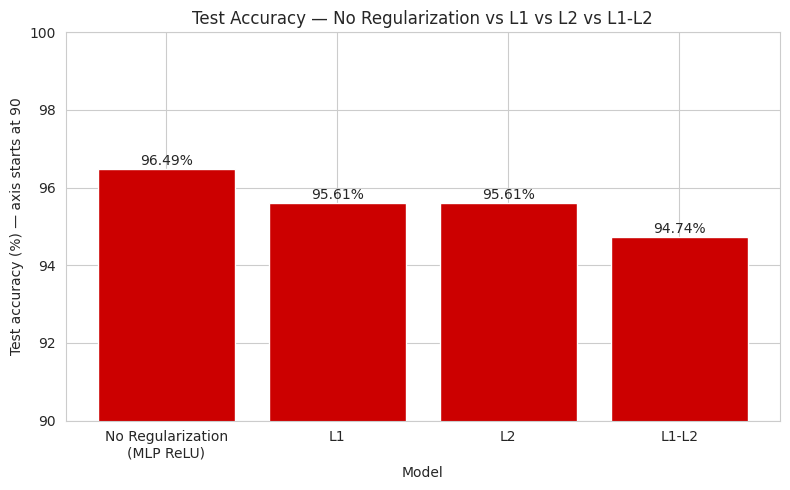

In [51]:
bar_names = [f"No Regularization\n(MLP {best_act})", "L1", "L2", "L1-L2"]
bar_values = [best_acc * 100, acc_l1 * 100, acc_l2 * 100, acc_l1l2 * 100]

plt.figure(figsize=(8, 5))
bars = plt.bar(bar_names, bar_values, color="#CC0000")

for bar in bars:
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.1, f"{bar.get_height():.2f}%", ha="center")

plt.ylim(90, 100)
plt.title("Test Accuracy — No Regularization vs L1 vs L2 vs L1-L2")
plt.xlabel("Model")
plt.ylabel("Test accuracy (%) — axis starts at 90")
plt.tight_layout()
plt.savefig("plots/regularization_accuracy_bar.png", dpi=120)
plt.show()

### Observation: Test Accuracy of Regularized Models

No regularization 96.49%, L1 95.61%, L2 95.61%, L1-L2 94.74%. The differences are only 1 or 2 test samples out of 114 (each sample is about 0.9%),
so regularization did not improve the test accuracy in this run. The dataset is small and fairly easy, and the MLP with Early Stopping is already generalising well.

## Task 7: Final Comparison, Business Insights & Notebook Quality
**Objective:** Combine Dropout, L2 and Early Stopping in one final model and compare all models.

**Expected output:** Final model, full results table and a clinical insight report.

### 7.1 - Best model: combine Dropout + L2 + Early Stopping

In [52]:
tf.keras.utils.set_random_seed(42)

final_model = keras.Sequential([
    keras.Input(shape=(30,)),
    keras.layers.Dense(128, activation="relu", kernel_regularizer=regularizers.l2(0.001)),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(64, activation="relu", kernel_regularizer=regularizers.l2(0.001)),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(1, activation="sigmoid")
])

final_model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])

es_final = EarlyStopping(monitor="val_loss", patience=20, restore_best_weights=True, verbose=1)

history_final = final_model.fit(X_train_sc, y_train, epochs=300, batch_size=32, validation_split=0.1, callbacks=[es_final], verbose=1)

Epoch 1/300


 1/13 ━━━━━━━━━━━━━━━━━━━━ 17s 1s/step - accuracy: 0.4375 - loss: 0.9193

13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 31ms/step - accuracy: 0.7800 - loss: 0.6317 - val_accuracy: 0.8913 - val_loss: 0.4693


Epoch 2/300


 1/13 ━━━━━━━━━━━━━━━━━━━━ 2s 240ms/step - accuracy: 0.9375 - loss: 0.4370

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.9487 - loss: 0.3585 - val_accuracy: 0.9130 - val_loss: 0.3605


... (462 outputs left out)

 1/13 ━━━━━━━━━━━━━━━━━━━━ 1s 123ms/step - accuracy: 1.0000 - loss: 0.0218

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.9976 - loss: 0.0305 - val_accuracy: 0.9783 - val_loss: 0.0450


Epoch 153: early stopping


Restoring model weights from the end of the best epoch: 133.


In [53]:
y_pred_final = (final_model.predict(X_test_sc, verbose=0) > 0.5).astype(int).ravel()
print(classification_report(y_test, y_pred_final, target_names=["Malignant (0)", "Benign (1)"]))

               precision    recall  f1-score   support

Malignant (0)       0.91      0.98      0.94        42
   Benign (1)       0.99      0.94      0.96        72

     accuracy                           0.96       114
    macro avg       0.95      0.96      0.95       114
 weighted avg       0.96      0.96      0.96       114



### 7.2 - Full results comparison table

In [54]:
# (name, model, architecture, regularization, dropout rate, early stopping)
all_models = [
    ("SLP (Task 2)", model_slp, "30-1", "None", 0.0, "No"),
    (f"MLP-{best_act} (Task 3)", best_mlp, "30-64-32-1", "None", 0.0, "No"),
    ("MLP + Early Stopping (Task 4)", model_es, "30-128-64-1", "None", 0.0, "Yes (patience=15)"),
    (f"MLP + Dropout-best (Task 5)", best_drop, "30-128-64-1", "None", best_rate, "Yes (patience=20)"),
    ("MLP + L2 (Task 6)", model_l2, "30-128-64-1", "L2 (0.001)", 0.0, "Yes (patience=20)"),
    ("Final Combined Model (Task 7.1)", final_model, "30-128-64-1", "L2 (0.001)", 0.3, "Yes (patience=20)"),
]

rows = []
for name, model, arch, reg, rate, stop in all_models:
    y_pred = (model.predict(X_test_sc, verbose=0) > 0.5).astype(int).ravel()
    rows.append({
        "Model": name,
        "Architecture": arch,
        "Regularization": reg,
        "Dropout Rate": rate,
        "Early Stopping": stop,
        "Test Accuracy": accuracy_score(y_test, y_pred),
        "Test Precision": precision_score(y_test, y_pred, pos_label=0),
        "Test Recall": recall_score(y_test, y_pred, pos_label=0),
        "Test F1-Score": f1_score(y_test, y_pred, pos_label=0)
    })

final_results = pd.DataFrame(rows)
metric_cols = ["Test Accuracy", "Test Precision", "Test Recall", "Test F1-Score"]

final_results.style.format("{:.4f}", subset=metric_cols).highlight_max(subset=["Test Accuracy", "Test F1-Score"], color="#ffcccc")

,Model,Architecture,Regularization,Dropout Rate,Early Stopping,Test Accuracy,Test Precision,Test Recall,Test F1-Score
0,SLP (Task 2),30-1,None,0.000000,No,0.9474,0.9500,0.9048,0.9268
1,MLP-ReLU (Task 3),30-64-32-1,None,0.000000,No,0.9649,0.9318,0.9762,0.9535
2,MLP + Early Stopping (Task 4),30-128-64-1,None,0.000000,Yes (patience=15),0.9649,0.9318,0.9762,0.9535
3,MLP + Dropout-best (Task 5),30-128-64-1,None,0.500000,Yes (patience=20),0.9561,0.9111,0.9762,0.9425
4,MLP + L2 (Task 6),30-128-64-1,L2 (0.001),0.000000,Yes (patience=20),0.9561,0.9111,0.9762,0.9425
5,Final Combined Model (Task 7.1),30-128-64-1,L2 (0.001),0.300000,Yes (patience=20),0.9561,0.9111,0.9762,0.9425


### 7.3 - Business insight report

In [55]:
# the model gives the probability of Benign (class 1), so a higher threshold makes it more careful about calling a tumour Benign
y_prob = final_model.predict(X_test_sc, verbose=0).ravel()

for t in [0.5, 0.7, 0.8, 0.9]:
    y_pred_t = (y_prob > t).astype(int)
    missed_malignant = ((y_test.values == 0) & (y_pred_t == 1)).sum()
    false_alarms = ((y_test.values == 1) & (y_pred_t == 0)).sum()
    print(f"Benign threshold {t}: missed malignant = {missed_malignant}, benign flagged as malignant = {false_alarms}")

Benign threshold 0.5: missed malignant = 1, benign flagged as malignant = 4
Benign threshold 0.7: missed malignant = 1, benign flagged as malignant = 4
Benign threshold 0.8: missed malignant = 1, benign flagged as malignant = 4
Benign threshold 0.9: missed malignant = 1, benign flagged as malignant = 6


## Clinical Insight for Medical Diagnosis Support

**Results first.** All the MLP models have the same malignant recall (0.9762, so 1 missed malignant tumour out of 42), while the SLP missed 4 (recall 0.9048).
The best accuracy and F1 are 0.9649 and 0.9535 (MLP-ReLU and MLP + Early Stopping), and the final combined model has 0.9561 and 0.9425.
These differences are one test sample, so they are within noise for a 114-sample test set.

**(a) Which model to deploy?** I would recommend the final combined model (Dropout + L2 + Early Stopping) over the SLP. The clearest gain in the whole project is going from the SLP to an MLP (fewer missed cancers).
Among the MLPs the test scores are practically tied, so I prefer the one with all three safeguards because it should be the most stable on new patients.
In cancer diagnosis a false negative (a missed malignant case) is far more costly than a false positive (an extra check), so recall of the Malignant class matters more than accuracy.
The final model's recall is 0.98 with precision 0.91 (4 benign cases flagged), which I think is an acceptable trade-off. A real tool would still need cross-validation and a doctor making the final decision.

**(b) Threshold.** The model outputs the probability of Benign (class 1). The default 0.5 means "call it Benign if the probability is above 0.5".
Being more careful about malignant cases means making this benign threshold **higher** (equivalent to flagging a case as malignant when its malignant probability is above about 0.2 to 0.3).
In my threshold test, thresholds from 0.5 to 0.8 gave the same result (1 missed malignant, 4 false alarms), and 0.9 only added false alarms (6) without catching more.
So the one missed tumour is a confident mistake that no threshold can fix. Still, I would use a safety margin of about 0.7 to 0.8 because it costs nothing on this test set, and I would send borderline cases to a doctor.

**(c) Which technique helped generalisation most?** Early Stopping had the clearest effect: the validation loss without it rose from 0.0301 to 0.0449 by epoch 300, and with it training stopped at the best point after 64 epochs.
Dropout and L1/L2 regularization did not improve the test accuracy in this run (all about 95% to 96%). The biggest improvement overall came from adding hidden layers (SLP to MLP), not from the regularization techniques.
This dataset is small and clean, so the benefit of regularization may simply be small here.